In [1]:
# pip install dash

In [2]:
import pandas as pd 
import numpy as np 
import datetime as dt 
import itertools
import plotly as py
import plotly.graph_objs as go
import plotly.figure_factory as ff
import plotly.express as px
from dash import Dash, dcc, html, Input, Output
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler

# Исследование вероятности выполнения заявок логистической компанией

Логистическая компания занимается оказанием услуг по железнодорожной перевозке.  
Ежедневно в компанию поступают заявки на транспортировку товаров. Для каждой заявки известно направление перевозки (между какими станциями нужно осуществить транспортировку товаров), объем товаров, требующих перевозку, планируемая дата отправки, учетное направление перевозки (некоторые особенности перевозки). В течение жизненного цикла заявки (от ее регистрации в системе до её закрытия) с ней могут происходить различные изменения: изменение станций отправки и доставки, изменение величины прибыли, получаемой компанией в результате осуществления услуги по доставке, отмена заявки и т.д. 
В конце месяца из существующих заявок формируется заявочная компания, которая передается в отдел оптимизации, который составляет расписание движения составов, которое старается выполнить весь объем поступивших заявок.

**Глобальная задача:** используя инструменты машинного обучения предсказать вероятность выполнения заявки в заявочной компании. 

**Задача на сегодня**: используя инструменты визуализации данных и статистического анализа выявить признаки, которые оказывают влияние выполнение заявки.

Вам дана информацию о том, как формировалась заявочная компания с 01.01.2023 по 30.09.2023. Для каждой заявки представлены все изменения, вносимые оператором и результат выполнения заявки (выполнение, перенос, отмена).

**Описание исходных данных:**
 -   `Идентификатор погрузки` - уникальный номер погрузки в системе данных компании;
 -   `Дата редактирования` - когда вносились изменения в информацию о заявке на выполнение погрузки;   
 -   `Версия погрузки` - номер редакции;
 -   `Оператор` -  человек, осуществляющий редактирование заявки;
 -   `Дата отправления` - планируемая дата отправки погрузки;        
 -   `Дата отправления факт` - фактическая дата отправки погрузки;
 -   `Учетное направление` - тип перевозки; 
 -   `Кластер назначения`- из какого региона двигается состав;     
 -   `Кластер отправления` -  в какой регион двигается состав; 
 -   `Код назначения` - станция откуда нужно перевести товары;           
 -   `Код отправления` - станция, куда нужно перевезти товары;         
 -   `Количество вагонов` - количество вагонов в составе;      
 -   `Контрибуция` - прибыль, которую получит компания за перевозку;                         
 -   `Идентификатор переноса` - была ли перенесена погрука (-1 – заявка отменена, 0 – заявка выполнена, 1 – заявка перенесена);
 -   `Длительность жизни` -  время, которое прошло между первой и последней редакцией заявки;
 -   `Время до отправки`  - время между последней редакцией перед отправкой и плановой датой отправки;            
 -   `Количество редакций после отправки`  - сколько раз заявка редактировалась после ее отправки;        
 -   `Количество отмен` - сколько раз заявка отменялась к моменту последней редакции заявки перед отправкой;       
 -   `Количество переносов` - сколько раз заявка переносилась к моменту последней редакции заявки перед отправкой;            
 -   `Среднее время между редакциями` - сколько дней проходило в среднем между редакциями. 
            
     

**Целевой признак (результат)**: статус выполнения заявки (1 -- если заявка выполнена, 0 -- если заявка не выполнена (перенесена, отменена)). 

In [3]:
df = pd.read_excel('orders_short_v3.xlsx')

# Исследовательский анализ

Начнем исследовательский анализ с рассмотрения количественных признаков. 
1. Определите, какие признаки относятся к количественным. Выведите их описательные статистики.
2. Выполните проверку на нормальность количественных признаков следующими методами:
   - постройте гистограмму;
   - постройте кумулятивное распределение;
   - постройте график квантиль-квантиль;
   - вычислите коэффициенты ассиметрии и эксцесса;
   - проведите тестирование данных на нормальность.
3. Для каждого способа проверки на нормальность сделайте выводы.
4. При выполнении графических видов проверки данных на нормальность, постройте динамичесий график с использованим библиотеку dash. При работе с диаграммой пользователь выбирает наименование количественного признака, для которого необходимо провести проверку на нормальность и тип диаграммы, а в результате получает нужный график, а ниже -- результат проведенного теста на нормальность. 

## Описательные статистики

In [4]:
df = df.rename(columns={'версия погрузки': 'Версия погрузки'})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3190 entries, 0 to 3189
Data columns (total 23 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Unnamed: 0                          3190 non-null   int64         
 1   Идентификатор погрузки              3190 non-null   int64         
 2   Дата редактирования                 3190 non-null   datetime64[ns]
 3   Версия погрузки                     3190 non-null   int64         
 4   Оператор                            3190 non-null   object        
 5   Дата отправления                    3190 non-null   datetime64[ns]
 6   Дата отправления факт               1826 non-null   datetime64[ns]
 7   Учетное направление                 3190 non-null   object        
 8   Кластер назначения                  3190 non-null   object        
 9   Кластер отправления                 3190 non-null   object        
 10  Код назначения          

In [5]:
# удалим столбец unnamed
df = df.iloc[:, 1:]
df.head(1)

,Идентификатор погрузки,Дата редактирования,Версия погрузки,Оператор,Дата отправления,Дата отправления факт,Учетное направление,Кластер назначения,Кластер отправления,Код назначения,...,Контрибуция,Идентификатор переноса,Длительность жизни,Время до отправки,Количество редакций после отправки,Количество отмен,Количество переносов,Среднее время между редакциями,Длительность афтершока,Результат
0,6832,2023-01-16 10:40:00,3,Antoshkinaa,2023-01-21,NaT,(8) ВРП,ДВ,СПб,98220,...,-1109524,-1,33.75,4.56,0,3,0,16.5,-4.56,0


In [6]:
df_n = df[['Контрибуция',
           'Длительность жизни',
           'Время до отправки',
           'Среднее время между редакциями',
           'Длительность афтершока']]
df_n.head(1)

,Контрибуция,Длительность жизни,Время до отправки,Среднее время между редакциями,Длительность афтершока
0,-1109524,33.75,4.56,16.5,-4.56


In [7]:
df_n.describe()

,Контрибуция,Длительность жизни,Время до отправки,Среднее время между редакциями,Длительность афтершока
count,3.190000e+03,3190.000000,3190.000000,3190.000000,3190.000000
mean,1.062770e+06,9.139006,10.191777,3.099542,-3.239984
std,2.476254e+06,10.854553,10.282935,5.142586,14.826444
min,-6.522400e+07,0.000000,0.070000,-1.000000,-44.480000
25%,0.000000e+00,0.000000,1.700000,0.000000,-11.537500
50%,0.000000e+00,5.095000,5.795000,1.200000,-0.750000
75%,1.974068e+06,15.282500,16.540000,4.000000,3.277500
max,1.519000e+07,61.820000,53.040000,42.000000,104.510000


## Проверка на нормальность

### Гистограмма

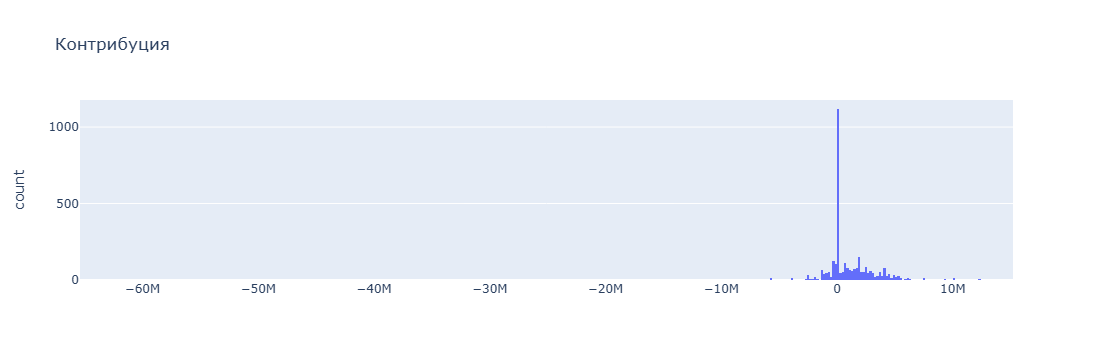

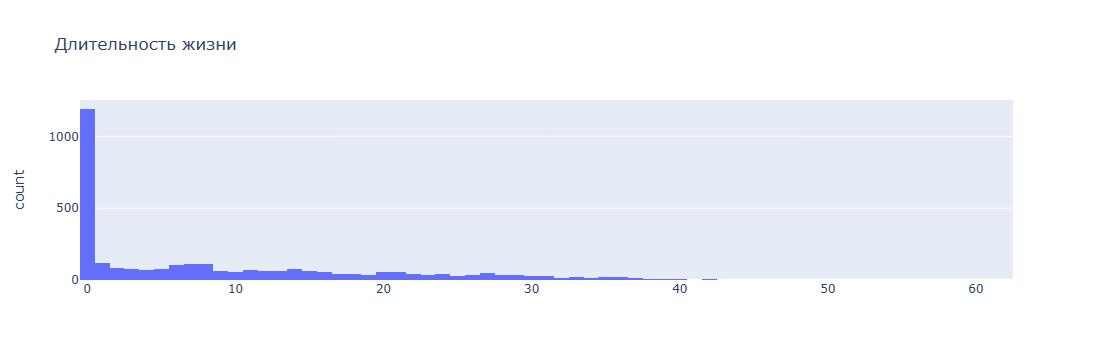

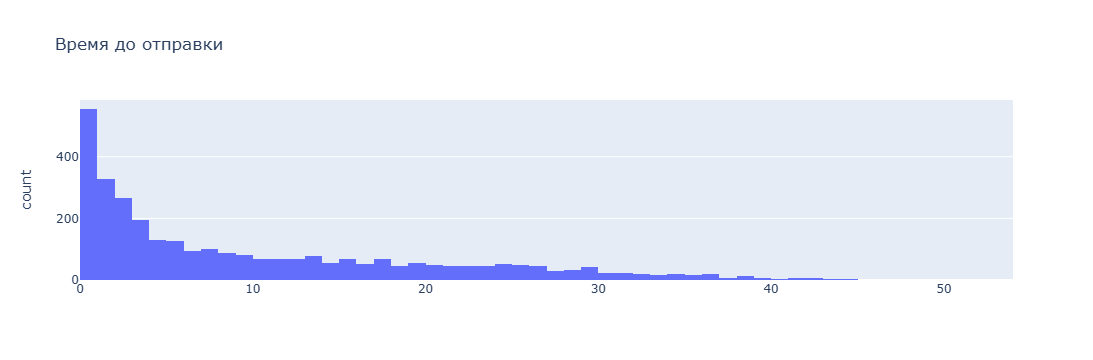

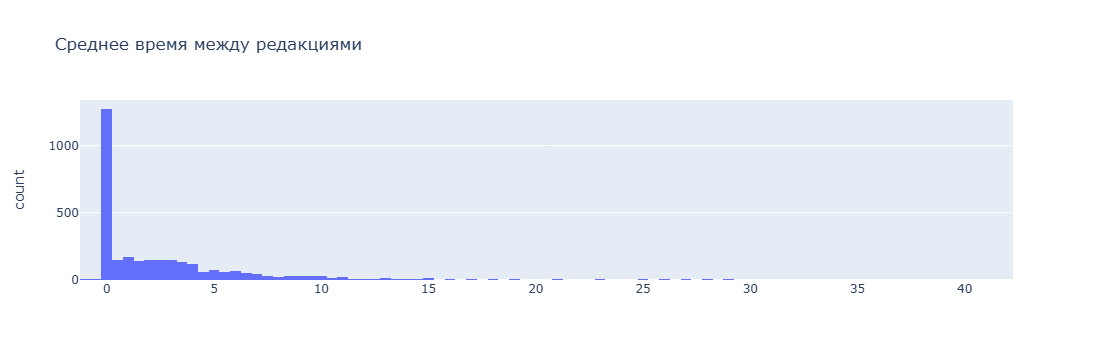

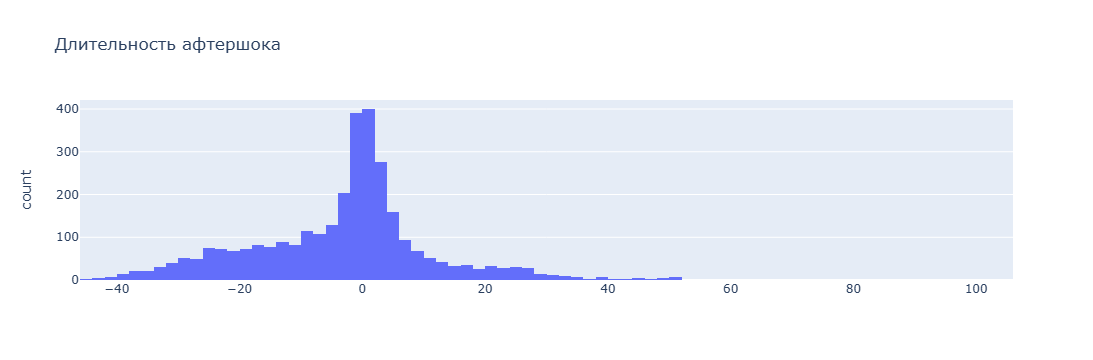

In [15]:
# x - столбец с данными
# name - название столбца
def histogram(x, name):
    fig = px.histogram(x=x, title=name)
    fig.update_xaxes(title='')
    return fig
for i in df_n.columns:
    histogram(df_n[i], i).show()

### Кумулятивное распределение

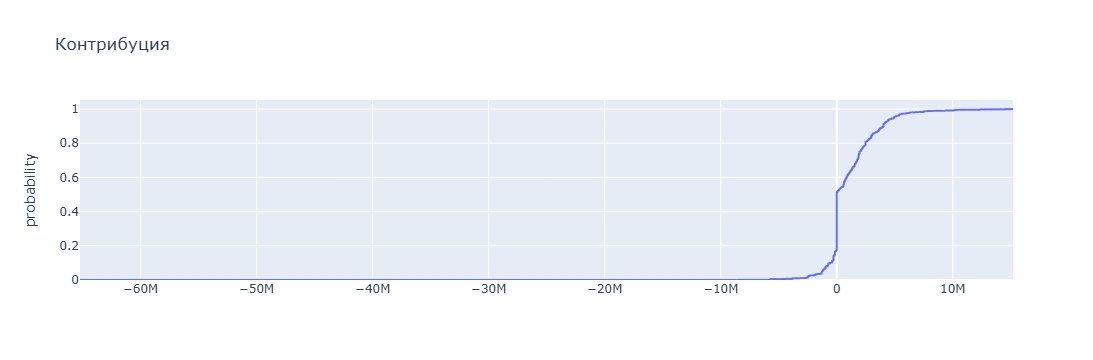

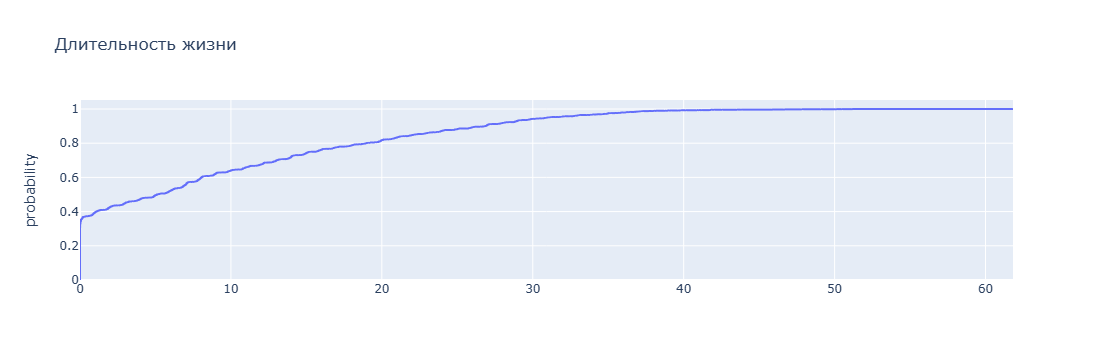

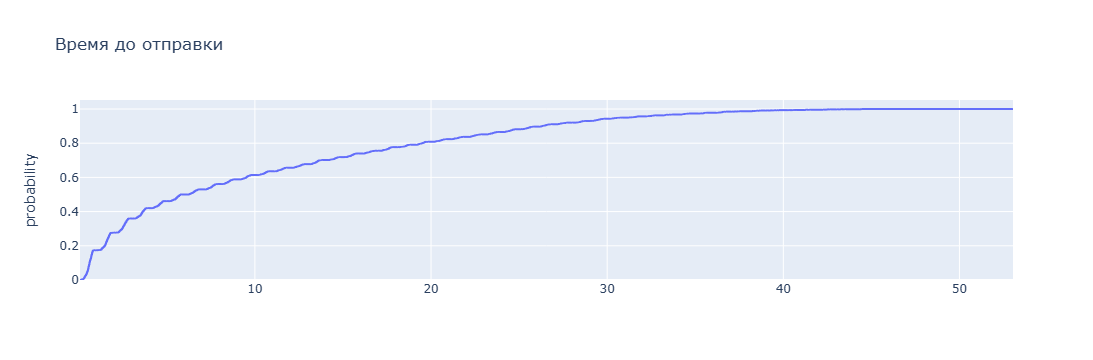

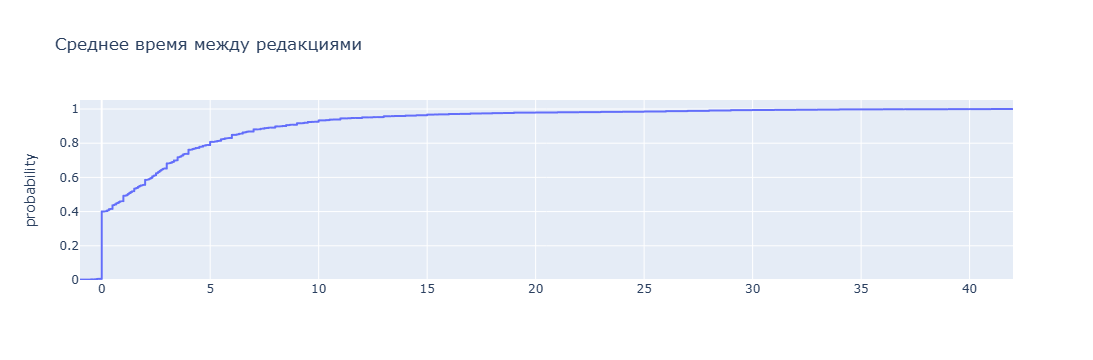

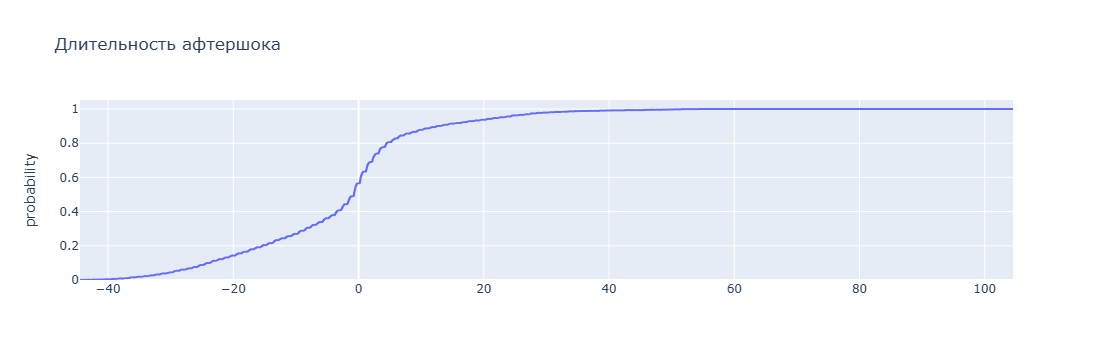

In [16]:
# x - столбец с данными
# name - название столбца
def ecdf(x, name):
    fig = px.ecdf(x=x, title=name)
    fig.update_xaxes(title='')
    return fig
for i in df_n.columns:
    ecdf(df_n[i], i).show()

### График квантиль -  квантиль

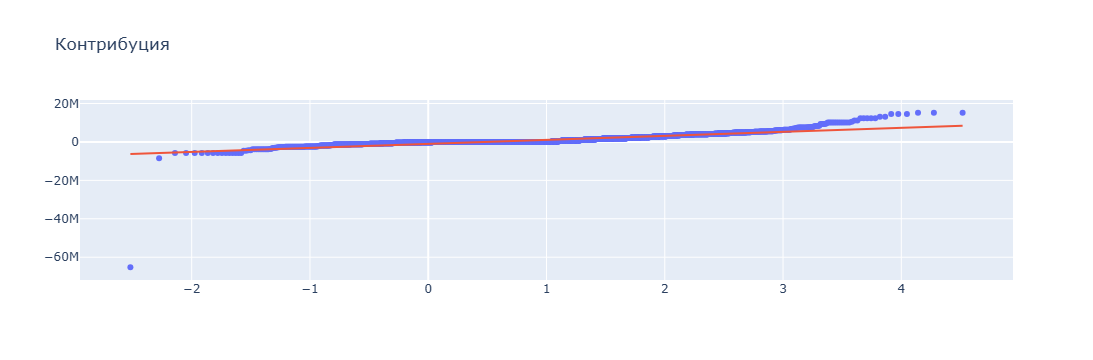

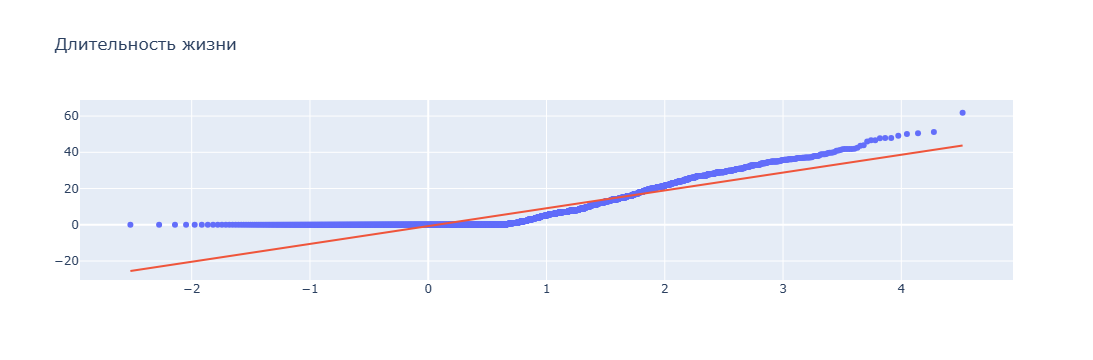

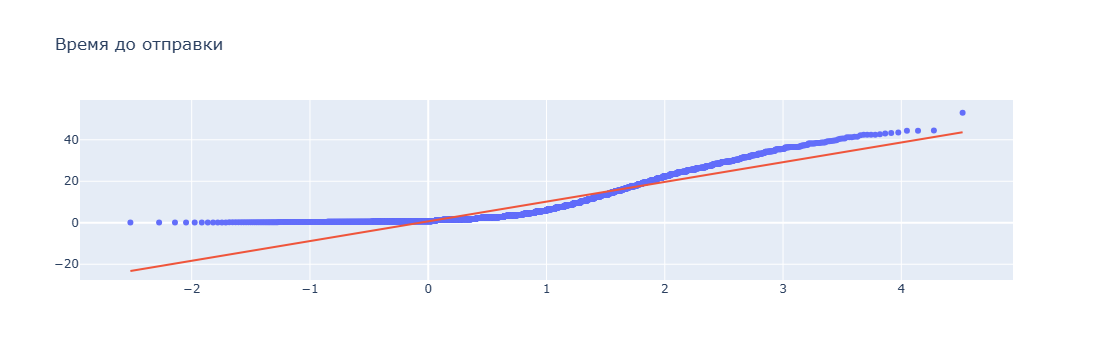

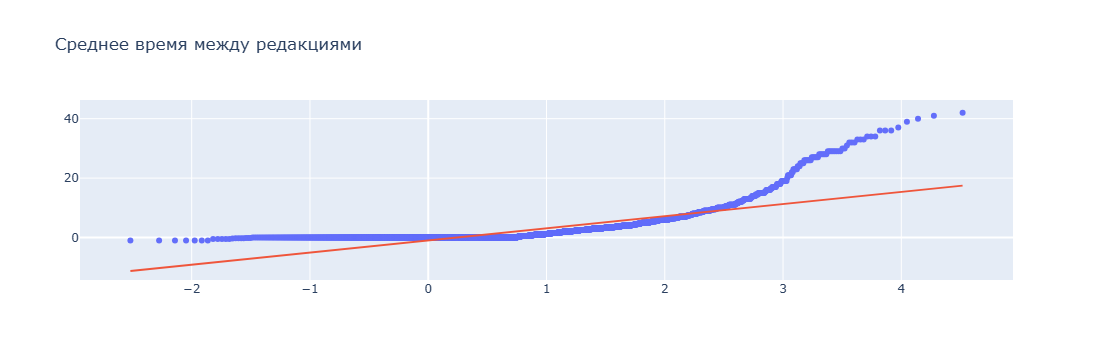

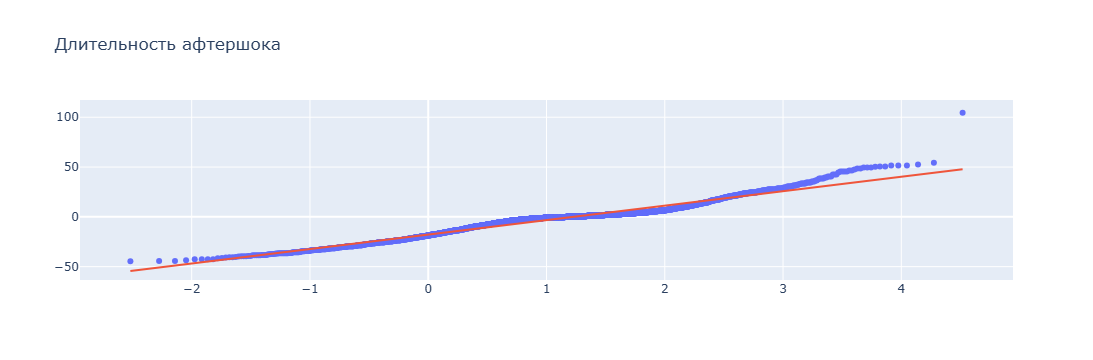

In [20]:
from scipy import stats
# x - столбец с данными
# name - название столбца

# Source - https://stackoverflow.com/a/51439172
# Posted by Sandu Ursu, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-08, License - CC BY-SA 4.0
def qq_plot(x, name):
    qq = stats.probplot(x, dist='norm', sparams=(1))
    x = np.array([qq[0][0][0], qq[0][0][-1]])
    
    fig = go.Figure()
    fig.add_scatter(x=qq[0][0], y=qq[0][1], mode='markers')
    fig.add_scatter(x=x, y=qq[1][1] + qq[1][0]*x, mode='lines')
    fig.layout.update(showlegend=False, title=name)
    return fig
    
for i in df_n.columns:
    qq_plot(df_n[i], i).show()

    


### Проверка с использованием коэффициентов ассиметрии и эксцесса

In [11]:
from scipy.stats import skew, kurtosis

def coef(x, name):
    s, k = skew(x), kurtosis(x)
    return s, k
for i in df_n.columns:
    s, k = coef(df_n[i], i)
    print(i)
    print('Асимметрия:', s)
    print('Эксцесс:', k)
    print()

Контрибуция
Асимметрия: -4.9196543968483395
Эксцесс: 163.58851484233497

Длительность жизни
Асимметрия: 1.133928239446145
Эксцесс: 0.45626062513430865

Время до отправки
Асимметрия: 1.0774473015318526
Эксцесс: 0.23874277454087922

Среднее время между редакциями
Асимметрия: 3.249226974094131
Эксцесс: 13.754637800750565

Длительность афтершока
Асимметрия: 0.24381967177278624
Эксцесс: 1.7775204106870248



### Проверка с использованием тестов

- тест Шапиро-Уилка – для небольших размеров выборки (<50 выборок)
- тест Колмогорова-Смирнова – для n ≥ 50

Для обоих вышеуказанных тестов нулевая гипотеза $H_0$ утверждает, что данные взяты из нормально распределенной совокупности.

In [12]:
from scipy.stats import kstest

def ks(x, name):
    x = (x - x.mean()) / x.std()
    p_value = kstest(x, 'norm').pvalue
    return p_value
         
for i in df_n.columns:
    p_value = ks(df_n[i], i)
    print(f'Колмогоров-Смирнов: {p_value}')
    if p_value > 0.05:
        print('Распределение нормальное: H₀ не отвергаем')
    else:
        print('Распределение не нормальное: H₀ отвергаем')
    print()

Колмогоров-Смирнов: 2.4602151743738703e-90
Распределение не нормальное: H₀ отвергаем

Колмогоров-Смирнов: 3.2798409419204653e-112
Распределение не нормальное: H₀ отвергаем

Колмогоров-Смирнов: 4.723208732939037e-77
Распределение не нормальное: H₀ отвергаем

Колмогоров-Смирнов: 2.1649619596084496e-201
Распределение не нормальное: H₀ отвергаем

Колмогоров-Смирнов: 4.473916381192428e-31
Распределение не нормальное: H₀ отвергаем



## Динамический график

### Выводы для dash

In [13]:
conclusions = {

'Контрибуция': {

'Гистограмма':
'Распределение крайне несимметрично. Более 50% наблюдений имеют значение 0, присутствуют крупные отрицательные и положительные выбросы.',

'Кумулятивное распределение':
'Наблюдается резкое накопление наблюдений вблизи нулевых значений, что свидетельствует о высокой концентрации данных в узком диапазоне.',

'График квантиль - квантиль':
'Точки значительно отклоняются от прямой линии, особенно в хвостах распределения, что указывает на сильное отличие от нормального закона.',

'Асимметрия и эксцесс':
'Асимметрия = -4.92, эксцесс = 163.59. Распределение имеет сильную левостороннюю асимметрию и большое количество выбросов.',

'Колмогоров-Смирнов':
'p-value < 0.05. Нулевая гипотеза отвергается, распределение не является нормальным.'
},


'Длительность жизни': {

'Гистограмма':
'Распределение имеет выраженную правостороннюю асимметрию. Большинство заявок имеют небольшую длительность жизни.',

'Кумулятивное распределение':
'Накопление наблюдений происходит быстро на малых значениях признака и замедляется на больших значениях.',

'График квантиль - квантиль':
'В центральной части точки расположены относительно близко к прямой, однако в хвостах наблюдаются отклонения.',

'Асимметрия и эксцесс':
'Асимметрия = 1.13, эксцесс = 0.46. Наблюдается умеренная правосторонняя асимметрия.',

'Колмогоров-Смирнов':
'p-value < 0.05. Нулевая гипотеза отвергается, распределение отличается от нормального.'
},


'Время до отправки': {

'Гистограмма':
'Распределение смещено вправо. Большая часть заявок отправляется в относительно короткий срок.',

'Кумулятивное распределение':
'Основная масса наблюдений сосредоточена в области небольших значений времени до отправки.',

'График квантиль - квантиль':
'Точки отклоняются от прямой линии, особенно на краях распределения.',

'Асимметрия и эксцесс':
'Асимметрия = 1.08, эксцесс = 0.24. Наблюдается умеренная правосторонняя асимметрия.',

'Колмогоров-Смирнов':
'p-value < 0.05. Нулевая гипотеза отвергается, распределение не является нормальным.'
},


'Среднее время между редакциями': {

'Гистограмма':
'Распределение имеет сильную правостороннюю асимметрию. Большинство изменений вносится через небольшие промежутки времени.',

'Кумулятивное распределение':
'Наблюдается быстрое накопление наблюдений на малых значениях и длинный правый хвост.',

'График квантиль - квантиль':
'Точки существенно отклоняются от прямой линии, особенно для больших значений признака.',

'Асимметрия и эксцесс':
'Асимметрия = 3.25, эксцесс = 13.75. Распределение сильно асимметрично и содержит выбросы.',

'Колмогоров-Смирнов':
'p-value < 0.05. Нулевая гипотеза отвергается, распределение отличается от нормального.'
},


'Длительность афтершока': {

'Гистограмма':
'Распределение относительно симметрично по сравнению с другими признаками, однако содержит длинные хвосты.',

'Кумулятивное распределение':
'Накопление наблюдений происходит достаточно равномерно в центральной части распределения.',

'График квантиль - квантиль':
'В центре распределения точки близки к прямой, однако в хвостах наблюдаются отклонения.',

'Асимметрия и эксцесс':
'Асимметрия = 0.24, эксцесс = 1.78. Асимметрия выражена слабо, однако хвосты распределения более тяжелые, чем у нормального.',

'Колмогоров-Смирнов':
'p-value < 0.05. Нулевая гипотеза отвергается, распределение не является нормальным.'
}

}

### Dash

In [21]:
app = Dash(__name__)

app.layout = html.Div([
    
    dcc.Dropdown(df_n.columns, df_n.columns[0], id='feature'),

    dcc.Dropdown(['Гистограмма',
                  'Кумулятивное распределение',
                  'График квантиль - квантиль',
                  'Асимметрия и эксцесс',
                  'Колмогоров-Смирнов'],
    'Гистограмма', id='test'),
    html.Div(id='output')])

@app.callback(
    Output('output', 'children'),
    Input('feature', 'value'),
    Input('test', 'value'))

def update(feature, test):

    x = df_n[feature]

    if test == 'Гистограмма':
        return [dcc.Graph(figure=histogram(x, feature)), html.Pre(conclusions[feature][test])]

    if test == 'Кумулятивное распределение':
        return [dcc.Graph(figure=ecdf(x, feature)), html.Pre(conclusions[feature][test])]

    if test == 'График квантиль - квантиль':
        return [dcc.Graph(figure=qq_plot(x, feature)), html.Pre(conclusions[feature][test])]

    if test == 'Асимметрия и эксцесс':
        s, k = skew(x), kurtosis(x)
        return [html.Pre(f'Асимметрия: {s:.4f}\nЭксцесс: {k:.4f}'), html.Pre(conclusions[feature][test])]

    if test == 'Колмогоров-Смирнов':
        p = kstest((x - x.mean()) / x.std(), 'norm').pvalue
        return [html.Pre(f'p-value: {p}'), html.Pre(conclusions[feature][test])]
    
app.run(debug=True)